# Spotify Dataset — Exploratory Data Analysis & Data Profiling

In [2]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
import numpy as np

## 🔍 Observations

- The dataset contains **114,000 tracks** and **21 columns**, providing a solid volume of data for analysis.
- Most fields are **100% complete**, while only **3 text columns** (`artists`, `album_name`, and `track_name`) contain missing values.
- The audio features, popularity, duration, and other numerical attributes are **fully populated**, supporting reliable analysis.
- The dataset combines **track information, musical characteristics, and popularity**, making it suitable for exploring patterns and relationships in Spotify music data.
- Overall, the dataset presents **good data quality** and provides a strong foundation for the next stages of analysis.

In [3]:
# Load Spotify data
spotify_df = pd.read_csv("../../data/raw/spotify_dataset.csv")

# Structural Overview
print(f"Spotify Dataset Shape: {spotify_df.shape}")
print("-" * 50)
spotify_df.info()



Spotify Dataset Shape: (114000, 21)
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-

In [4]:
# The first 5 rows of the dataframe
spotify_df.head()


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### Null values

In [5]:
spotify_df.isnull().sum()

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
energy              0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
dtype: int64

In [6]:
# Missing Values Analysis (Spotify)
# Missing Values Analysis (Spotify)
spotify_nulls = spotify_df.isnull().sum()

print("Missing values per column:")
spotify_nulls = spotify_df.isnull().sum()
print(spotify_nulls[spotify_nulls > 0])



Missing values per column:
artists       1
album_name    1
track_name    1
dtype: int64


In [7]:


# Null values analysis
df_sp = spotify_df

nulls_sp = df_sp.isnull().sum()
nulls_percentage_sp = (nulls_sp / len(df_sp)) * 100
df_null_sp = pd.DataFrame({'Nulls': nulls_sp, 'Percentage (%)': nulls_percentage_sp})
print(df_null_sp)

# Show only columns with null value
display(df_null_sp[df_null_sp['Nulls'] > 0].sort_values(by='Percentage (%)', ascending=False))



                  Nulls  Percentage (%)
Unnamed: 0            0        0.000000
track_id              0        0.000000
artists               1        0.000877
album_name            1        0.000877
track_name            1        0.000877
popularity            0        0.000000
duration_ms           0        0.000000
explicit              0        0.000000
danceability          0        0.000000
energy                0        0.000000
key                   0        0.000000
loudness              0        0.000000
mode                  0        0.000000
speechiness           0        0.000000
acousticness          0        0.000000
instrumentalness      0        0.000000
liveness              0        0.000000
valence               0        0.000000
tempo                 0        0.000000
time_signature        0        0.000000
track_genre           0        0.000000


,Nulls,Percentage (%)
artists,1,0.000877
album_name,1,0.000877
track_name,1,0.000877


In [8]:
spotify_df[spotify_df["artists"].isnull()]


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
65900,65900,1kR4gIb7nGxHPI3D2ifs59,NaN,NaN,NaN,0,0,False,0.501,0.583,...,-9.46,0,0.0605,0.69,0.00396,0.0747,0.734,138.391,4,k-pop


## Missing Values Analysis (Spotify)

In [9]:
duplicated_values = spotify_df.duplicated()
duplicated_values.sum()


np.int64(0)

In [10]:
total_duplicated_sp = spotify_df.duplicated().sum()
print(f"{total_duplicated_sp} rows were found that were exactly the same")

if total_duplicated_sp > 0:
    # sample of some duplicated rows
    display(spotify_df[spotify_df.duplicated(keep=False)].sort_values(by='track_id').head(4))

0 rows were found that were exactly the same


In [11]:
genre_counts = spotify_df["track_genre"].value_counts().reset_index()

genre_counts.columns = ["track_genre", "total_tracks"]

genre_counts

,track_genre,total_tracks
0,acoustic,1000
1,afrobeat,1000
2,alt-rock,1000
3,alternative,1000
4,ambient,1000
...,...,...
109,techno,1000
110,trance,1000
111,trip-hop,1000
112,turkish,1000


# Basic Descriptive Statistics (Spotify)

In [12]:
genre_counts["total_tracks"].describe()

count     114.0
mean     1000.0
std         0.0
min      1000.0
25%      1000.0
50%      1000.0
75%      1000.0
max      1000.0
Name: total_tracks, dtype: float64

In [13]:
spotify_df["track_genre"].value_counts().value_counts()

count
1000    114
Name: count, dtype: int64

In [14]:
spotify_df.select_dtypes(include=["object", "string"]).describe()

,track_id,artists,album_name,track_name,track_genre
count,114000,113999,113999,113999,114000
unique,89741,31437,46589,73608,114
top,6S3JlDAGk3uu3NtZbPnuhS,The Beatles,Alternative Christmas 2022,Run Rudolph Run,acoustic
freq,9,279,195,151,1000


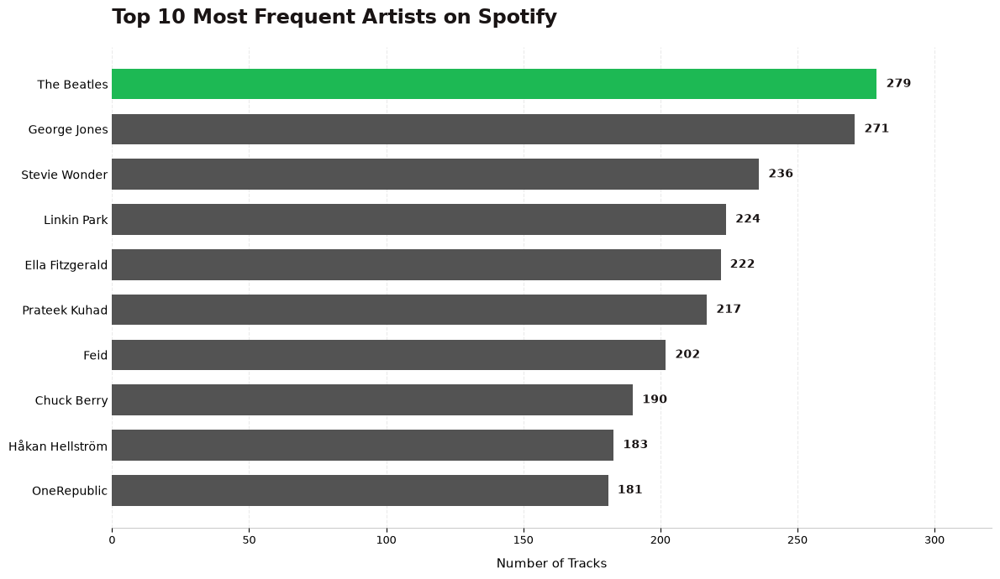

In [15]:

# Top 10 artists
top_artists = spotify_df["artists"].value_counts().head(10).sort_values()

# Spotify-inspired colors
spotify_green = "#1DB954"
spotify_dark = "#191414"
bar_colors = ["#535353"] * (len(top_artists) - 1) + [spotify_green]

# Figure
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Horizontal bar chart
bars = ax.barh(
    top_artists.index,
    top_artists.values,
    color=bar_colors,
    height=0.68
)

# Values at the end of each bar
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in top_artists.values],
    padding=8,
    fontsize=10,
    fontweight="bold",
    color=spotify_dark
)

# Titles and labels
ax.set_title(
    "Top 10 Most Frequent Artists on Spotify",
    fontsize=17,
    fontweight="bold",
    color=spotify_dark,
    loc="left",
    pad=20
)

ax.set_xlabel("Number of Tracks", fontsize=11, labelpad=10)
ax.set_ylabel("")

# Clean analytical style
ax.xaxis.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)

ax.tick_params(axis="y", labelsize=10, length=0)
ax.tick_params(axis="x", labelsize=9)

# Space for value labels
ax.set_xlim(0, top_artists.max() * 1.15)

plt.tight_layout()
plt.show()

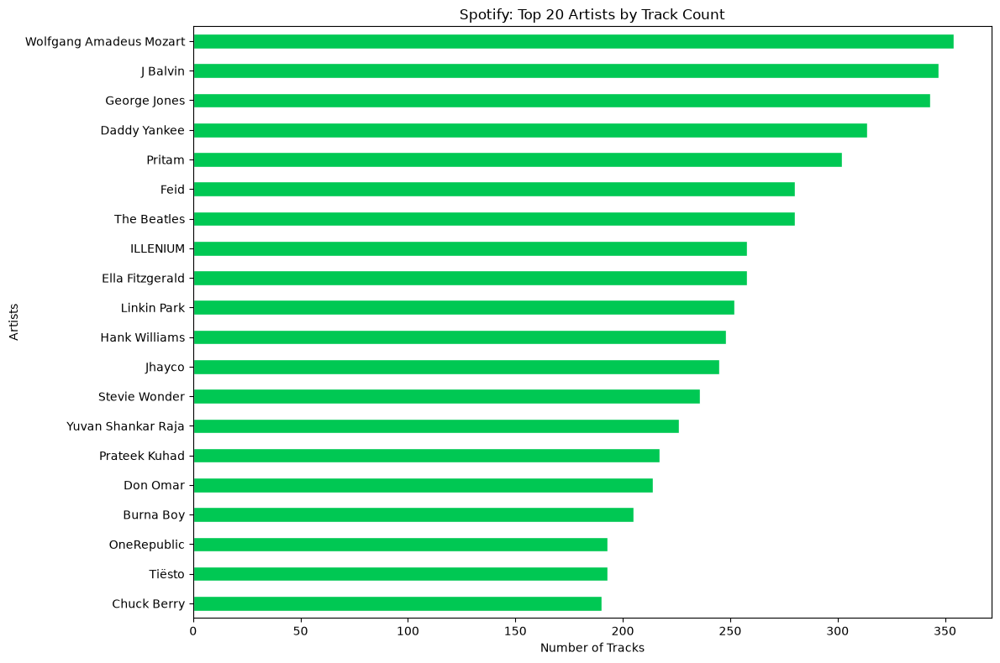

In [16]:
# Top 20 artists by number of tracks
top_artists = (
    df_sp["artists"]
    .dropna()
    .str.split(";")
    .str[0]
    .str.strip()
    .value_counts()
    .head(20)
)

fig, ax = plt.subplots(figsize=(12, 8))

top_artists.sort_values().plot.barh(
    ax=ax,
    color="#00C853",
    edgecolor="white"
)

ax.set_xlabel("Number of Tracks")
ax.set_ylabel("Artists")
ax.set_title("Spotify: Top 20 Artists by Track Count")

plt.tight_layout()
plt.show()

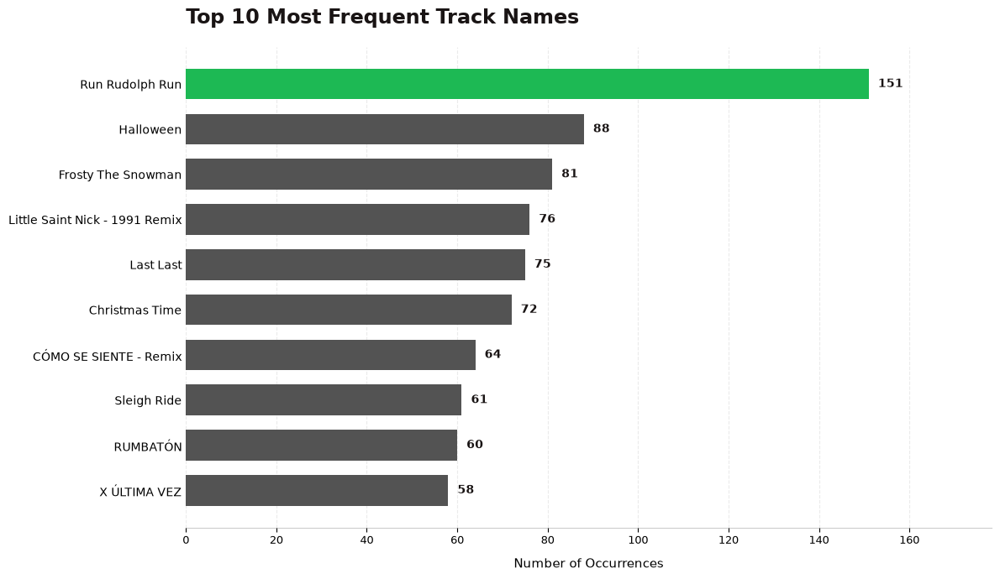

In [17]:


# Top 10 most frequent track names
top_tracks = spotify_df["track_name"].value_counts().head(10).sort_values()

# Spotify-inspired palette
spotify_green = "#1DB954"
spotify_dark = "#191414"
bar_colors = ["#535353"] * (len(top_tracks) - 1) + [spotify_green]

# Create figure
fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

# Horizontal bar chart
bars = ax.barh(
    top_tracks.index,
    top_tracks.values,
    color=bar_colors,
    height=0.68
)

# Add values at the end of each bar
ax.bar_label(
    bars,
    labels=[f"{value:,}" for value in top_tracks.values],
    padding=8,
    fontsize=10,
    fontweight="bold",
    color=spotify_dark
)

# Chart title and labels
ax.set_title(
    "Top 10 Most Frequent Track Names",
    fontsize=17,
    fontweight="bold",
    color=spotify_dark,
    loc="left",
    pad=20
)

ax.set_xlabel("Number of Occurrences", fontsize=11, labelpad=10)
ax.set_ylabel("")

# Minimalist analytical style
ax.xaxis.grid(True, linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)

ax.tick_params(axis="y", labelsize=10, length=0)
ax.tick_params(axis="x", labelsize=9)

# Leave room for data labels
ax.set_xlim(0, top_tracks.max() * 1.18)

plt.tight_layout()
plt.show()

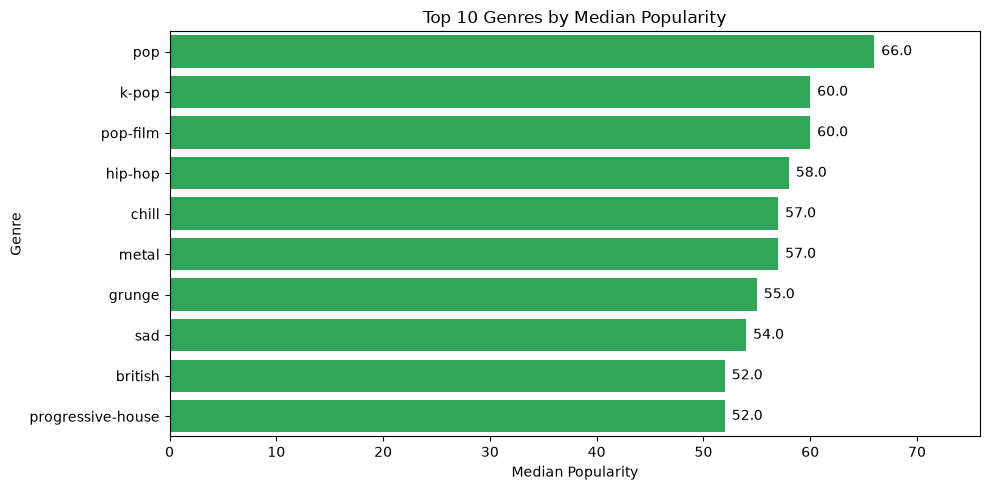

In [18]:
top_genres = (
    spotify_df.groupby("track_genre")["popularity"]
    .median()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=top_genres,
    x="popularity",
    y="track_genre",
    color="#1DB954",
)

# Add value labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=5)

plt.title("Top 10 Genres by Median Popularity")
plt.xlabel("Median Popularity")
plt.ylabel("Genre")
plt.xlim(0, top_genres["popularity"].max() * 1.15)

plt.tight_layout()
plt.show()

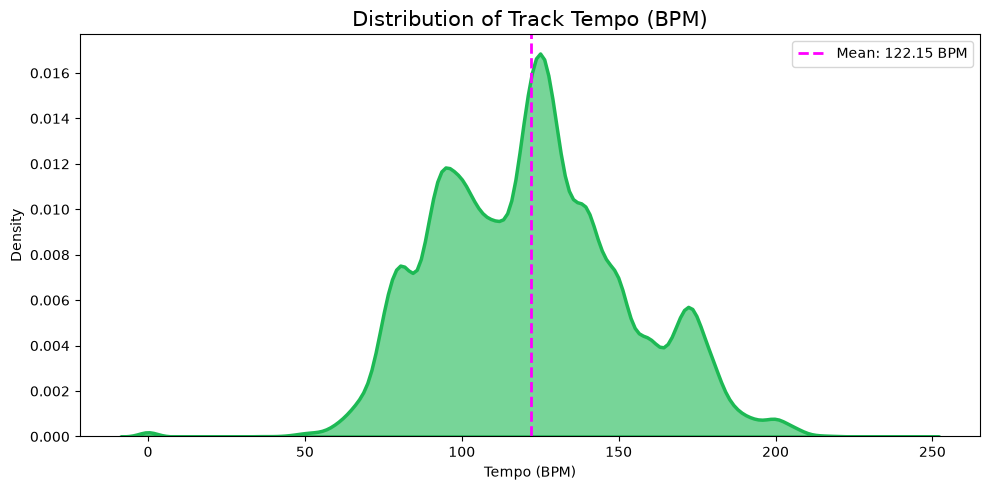

In [19]:
tempo = spotify_df['tempo'].dropna()
mean_tempo = tempo.mean()

plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=tempo,
    fill=True,
    color='#1DB954',
    linewidth=2.5,
    alpha=0.6
)

plt.axvline(
    mean_tempo,
    color='#FF00FF',
    linestyle='--',
    linewidth=2,
    label=f'Mean: {mean_tempo:.2f} BPM'
)

plt.title('Distribution of Track Tempo (BPM)', fontsize=15)
plt.xlabel('Tempo (BPM)')
plt.ylabel('Density')
plt.legend()
plt.tight_layout()
plt.show()

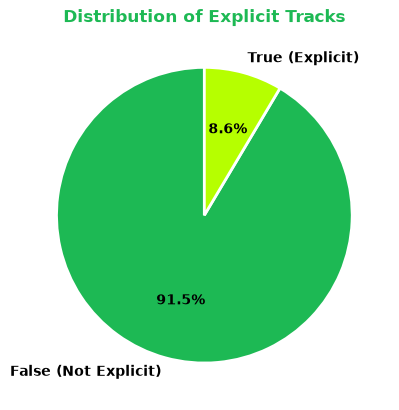

In [20]:
counts = spotify_df['explicit'].value_counts().reindex([False, True])

plt.pie(
    counts,
    labels=['False (Not Explicit)', 'True (Explicit)'],
    autopct='%1.1f%%',
    startangle=90,
    colors=['#1DB954', '#B6FF00'],
    textprops={'color': 'black', 'weight': 'bold'},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

plt.title('Distribution of Explicit Tracks', color='#1DB954', fontweight='bold')
plt.show()

/tmp/ipykernel_7545/684354870.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


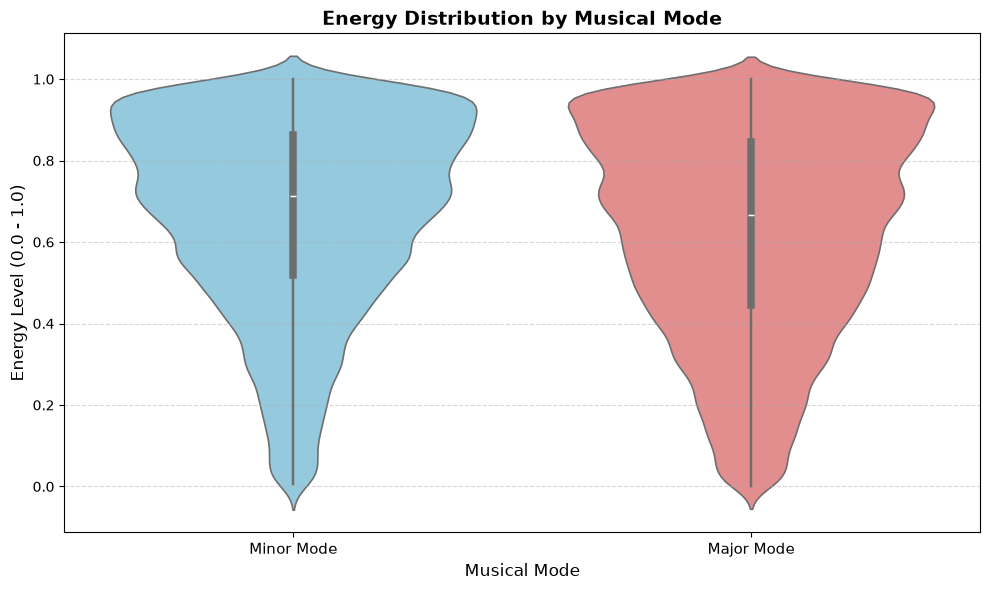

In [21]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=spotify_df,
    x="mode",           # Variable categórica (0 = Minor, 1 = Major)
    y="energy",         # Variable numérica
    palette={"0": "skyblue", "1": "lightcoral"},
    inner="box",        # Muestra la caja (Q1, mediana, Q3) dentro del violín
    linewidth=1.2
)

# Personalización
plt.title("Energy Distribution by Musical Mode", fontsize=14, fontweight='bold')
plt.xlabel("Musical Mode", fontsize=12)
plt.ylabel("Energy Level (0.0 - 1.0)", fontsize=12)
plt.xticks([0, 1], ["Minor Mode", "Major Mode"], fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

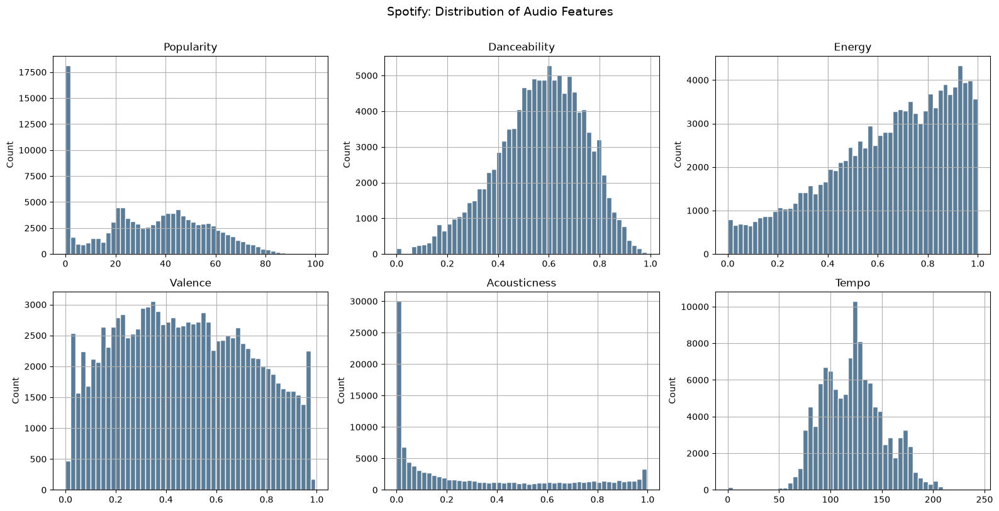

In [22]:
# Distribution of key numeric features
numeric_cols = ["popularity", "danceability", "energy", "valence", "acousticness", "tempo"]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flatten(), numeric_cols):
    df_sp[col].hist(bins=50, ax=ax, color="#5b7c99", edgecolor="white")
    ax.set_title(col.capitalize(), fontsize=12)
    ax.set_ylabel("Count")

fig.suptitle("Spotify: Distribution of Audio Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

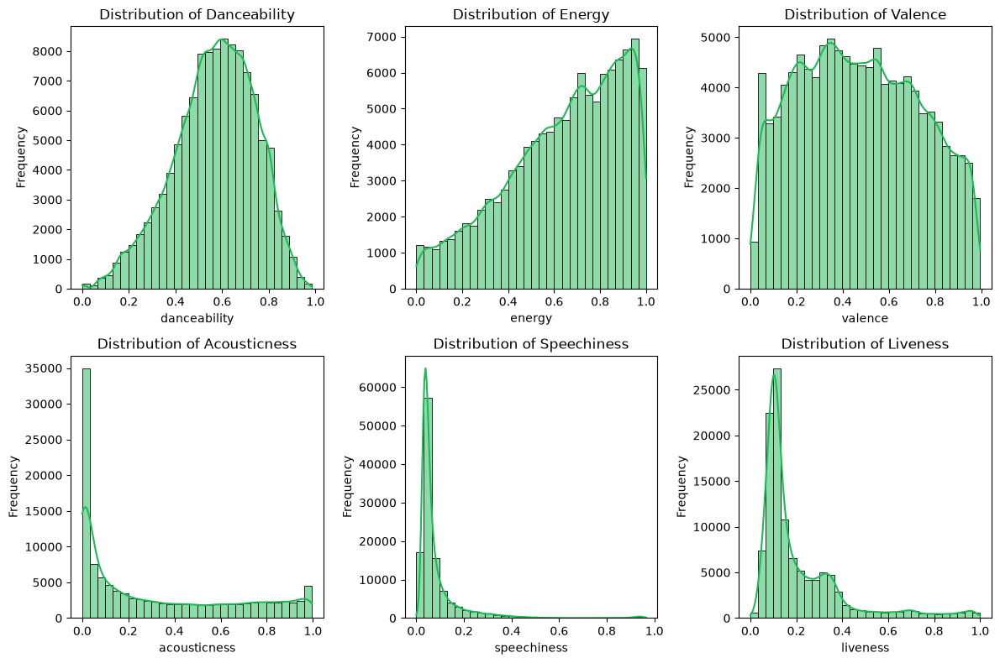

In [23]:
audio_features = [
    "danceability",
    "energy",
    "valence",
    "acousticness",
    "speechiness",
    "liveness",
]

plt.figure(figsize=(12, 8))

for i, feature in enumerate(audio_features, 1):
    plt.subplot(2, 3, i)

    sns.histplot(
        spotify_df[feature].dropna(),
        bins=30,
        kde=True,
        color="#1DB954",
    )

    plt.title(f"Distribution of {feature.capitalize()}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

count    31437.00
mean         3.63
std          8.79
min          1.00
25%          1.00
50%          1.00
75%          3.00
max        279.00
Name: count, dtype: float64

Artists with only 1 track: 16,767


/tmp/ipykernel_7545/2988285495.py:17: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot(


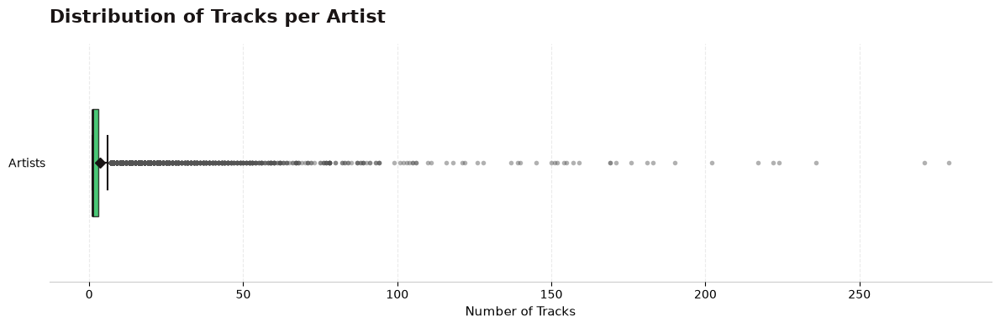

In [24]:


# Count tracks per artist
tracks_per_artist = spotify_df["artists"].value_counts()

# Summary statistics
print(tracks_per_artist.describe().round(2))
print(f"\nArtists with only 1 track: {(tracks_per_artist == 1).sum():,}")

# Spotify-inspired colors
spotify_green = "#1DB954"
spotify_dark = "#191414"

# Create boxplot
fig, ax = plt.subplots(figsize=(12, 4))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")

box = ax.boxplot(
    tracks_per_artist,
    vert=False,
    patch_artist=True,
    widths=0.45,
    showmeans=True,
    meanprops={
        "marker": "D",
        "markerfacecolor": spotify_dark,
        "markeredgecolor": spotify_dark,
        "markersize": 6
    },
    medianprops={
        "color": spotify_dark,
        "linewidth": 2
    },
    boxprops={
        "facecolor": spotify_green,
        "edgecolor": spotify_dark,
        "alpha": 0.8
    },
    whiskerprops={"color": spotify_dark, "linewidth": 1.5},
    capprops={"color": spotify_dark, "linewidth": 1.5},
    flierprops={
        "marker": "o",
        "markerfacecolor": "#535353",
        "markeredgecolor": "none",
        "markersize": 4,
        "alpha": 0.45
    }
)

ax.set_title(
    "Distribution of Tracks per Artist",
    fontsize=16,
    fontweight="bold",
    color=spotify_dark,
    loc="left",
    pad=18
)

ax.set_xlabel("Number of Tracks", fontsize=11)
ax.set_yticks([1])
ax.set_yticklabels(["Artists"], fontsize=10)

ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_alpha(0.2)

ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", labelsize=10)

plt.tight_layout()
plt.show()

### 📊 Spotify Popularity — Quartiles

The boxplot helps us understand how popularity is distributed across Spotify songs.

- **Q1 (17):** 25% of songs have a popularity score of 17 or less.
- **Median (35):** 50% of songs have a score of 35 or less.
- **Q3 (50):** 75% of songs have a score of 50 or less.

**Conclusion:** The middle 50% of songs have popularity scores between 17 and 50, showing that many songs have low-to-moderate popularity.

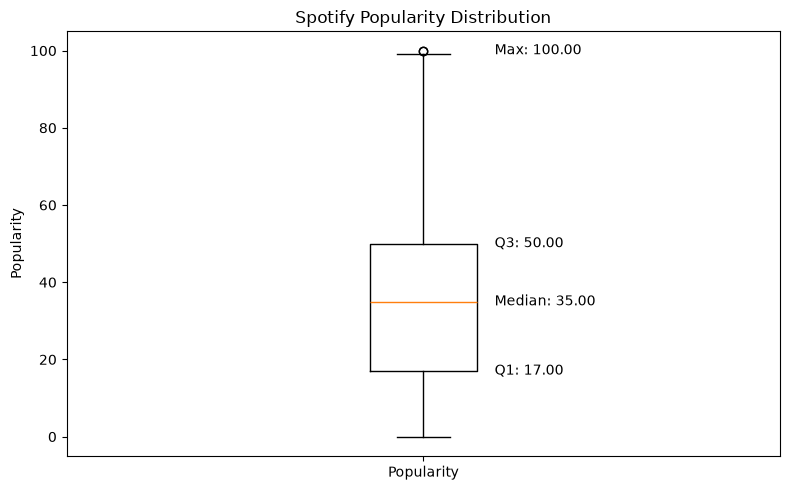

In [25]:

plt.figure(figsize=(8, 5))

data = spotify_df["popularity"].dropna()

plt.boxplot(data)

# Calculate quartiles and maximum
Q1 = data.quantile(0.25)
median = data.median()
Q3 = data.quantile(0.75)
maximum = data.max()

# Display values on the chart
plt.text(1.1, Q1, f'Q1: {Q1:.2f}', va='center')
plt.text(1.1, median, f'Median: {median:.2f}', va='center')
plt.text(1.1, Q3, f'Q3: {Q3:.2f}', va='center')
plt.text(1.1, maximum, f'Max: {maximum:.2f}', va='center')

plt.title("Spotify Popularity Distribution")
plt.ylabel("Popularity")
plt.xticks([1], ["Popularity"])
plt.tight_layout()
plt.show()


In [26]:
display(spotify_df[["popularity"]].describe().T)

,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.0,17.0,35.0,50.0,100.0


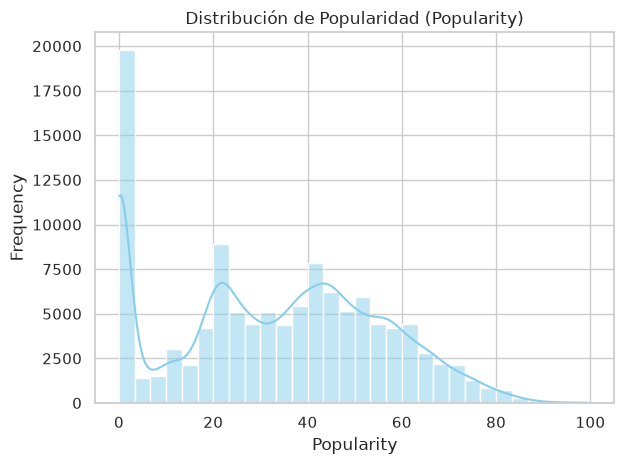

In [27]:
sns.set_theme(style="whitegrid")

sns.histplot(spotify_df["popularity"], bins=30, kde=True, color="skyblue")

plt.title("Distribución de Popularidad (Popularity)")
plt.xlabel("Popularity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

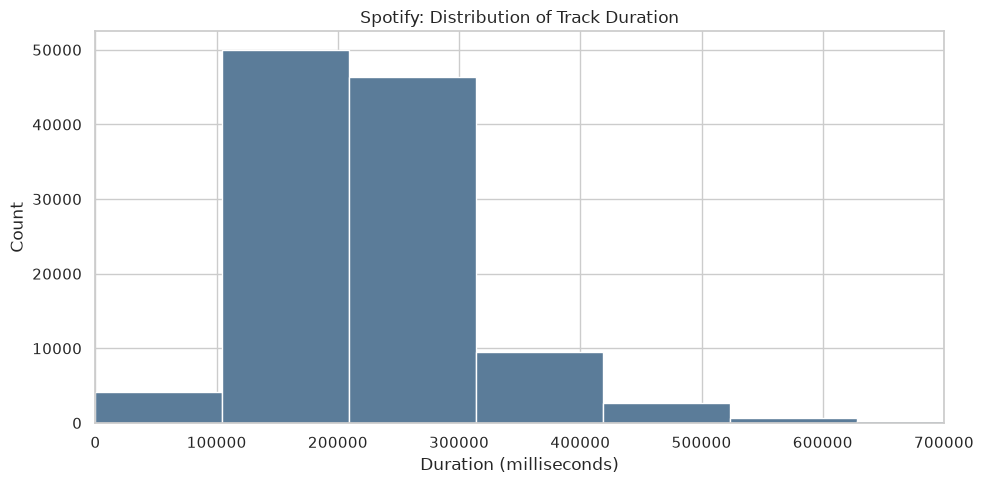

In [28]:
# Distribution of track duration
plt.figure(figsize=(10, 5))

df_sp["duration_ms"].hist(
    bins=50,
    color="#5b7c99",
    edgecolor="white"
)

plt.title("Spotify: Distribution of Track Duration")
plt.xlabel("Duration (milliseconds)")
plt.ylabel("Count")

plt.xlim(0, 700000)  # Limit X-axis to 10 minutes

plt.tight_layout()
plt.show()

/tmp/ipykernel_7545/2953469854.py:6: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(data, vert=True, patch_artist=True,


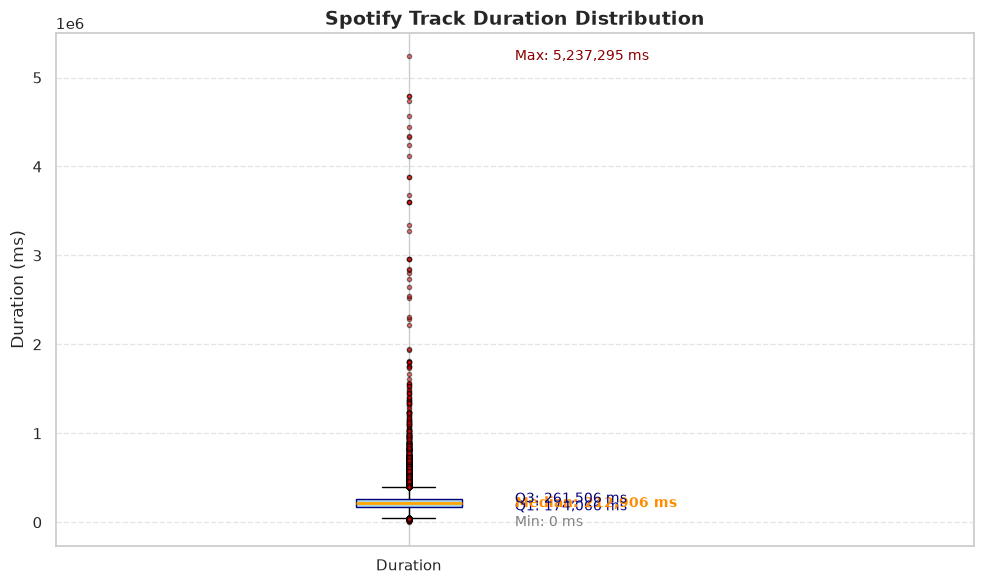

In [29]:


plt.figure(figsize=(10, 6))

data = spotify_df["duration_ms"].dropna()

# Create the boxplot
plt.boxplot(data, vert=True, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='navy'),
            medianprops=dict(color='orange', linewidth=2),
            flierprops=dict(marker='o', markerfacecolor='red', markersize=3, alpha=0.5))

# Calculate statistics
Q1 = data.quantile(0.25)
median = data.median()
Q3 = data.quantile(0.75)
maximum = data.max()
minimum = data.min()

# Place labels on the right side with visual separation
x_pos = 1.15
plt.text(x_pos, Q1, f'Q1: {Q1:,.0f} ms', va='center', fontsize=10, color='navy')
plt.text(x_pos, median, f'Median: {median:,.0f} ms', va='center', fontsize=10, color='darkorange', fontweight='bold')
plt.text(x_pos, Q3, f'Q3: {Q3:,.0f} ms', va='center', fontsize=10, color='navy')
plt.text(x_pos, maximum, f'Max: {maximum:,.0f} ms', va='center', fontsize=10, color='darkred')
plt.text(x_pos, minimum, f'Min: {minimum:,.0f} ms', va='center', fontsize=10, color='gray')

# Title and labels
plt.title("Spotify Track Duration Distribution", fontsize=14, fontweight='bold')
plt.ylabel("Duration (ms)", fontsize=12)
plt.xticks([1], ["Duration"], fontsize=11)

# Adjust X-axis limits to fit the labels
plt.xlim(0.5, 1.8)

# Add a soft grid on the Y-axis
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [30]:
display(spotify_df[["duration_ms"]].describe().T) 

,count,mean,std,min,25%,50%,75%,max
duration_ms,114000.0,228029.153114,107297.712645,0.0,174066.0,212906.0,261506.0,5237295.0


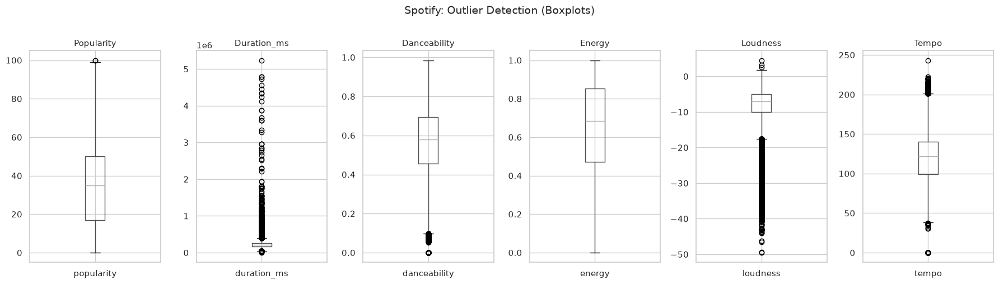

In [31]:

# Boxplots to detect outliers in numeric features
numeric_cols = [
    "popularity",
    "duration_ms",
    "danceability",
    "energy",
    "loudness",
    "tempo",
]
fig, axes = plt.subplots(1, 6, figsize=(18, 5))
for ax, col in zip(axes.flatten(), numeric_cols):
    df_sp.boxplot(column=col, ax=ax, vert=True)
    ax.set_title(col.capitalize(), fontsize=11)

fig.suptitle("Spotify: Outlier Detection (Boxplots)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()



In [32]:

display(spotify_df.select_dtypes(include='number').describe().T)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,114000.0,56999.500000,32909.109681,0.000,28499.75000,56999.500000,85499.2500,113999.000
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996


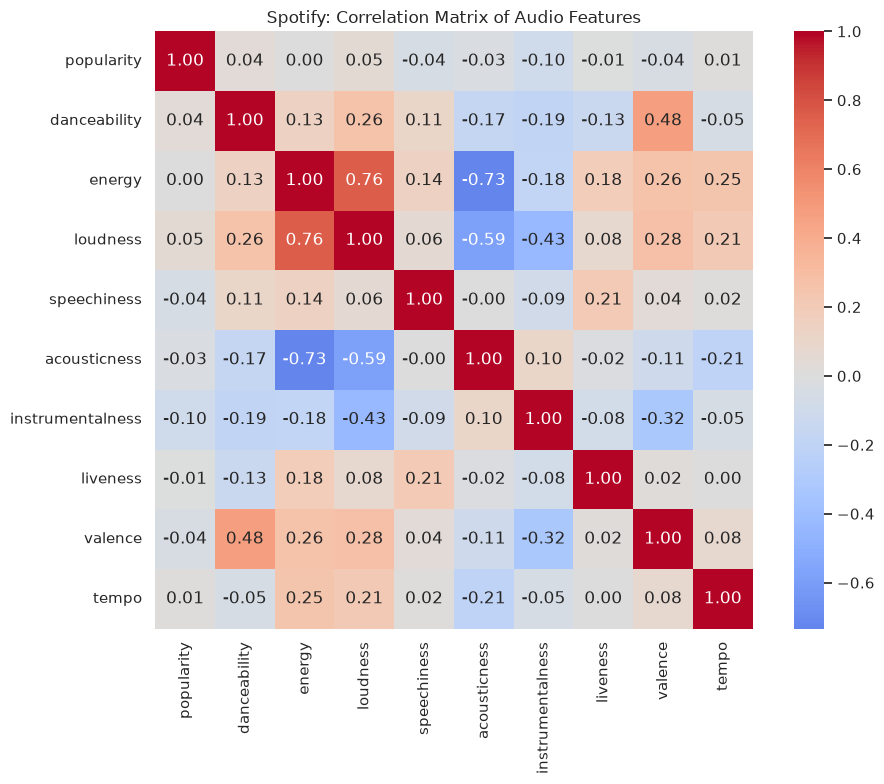

In [33]:
# Correlation heatmap of audio features
audio_features = ["popularity", "danceability", "energy", "loudness", "speechiness",
                  "acousticness", "instrumentalness", "liveness", "valence", "tempo"]

fig, ax = plt.subplots(figsize=(10, 8))
corr = df_sp[audio_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, square=True)
ax.set_title("Spotify: Correlation Matrix of Audio Features")
plt.tight_layout()
plt.show()

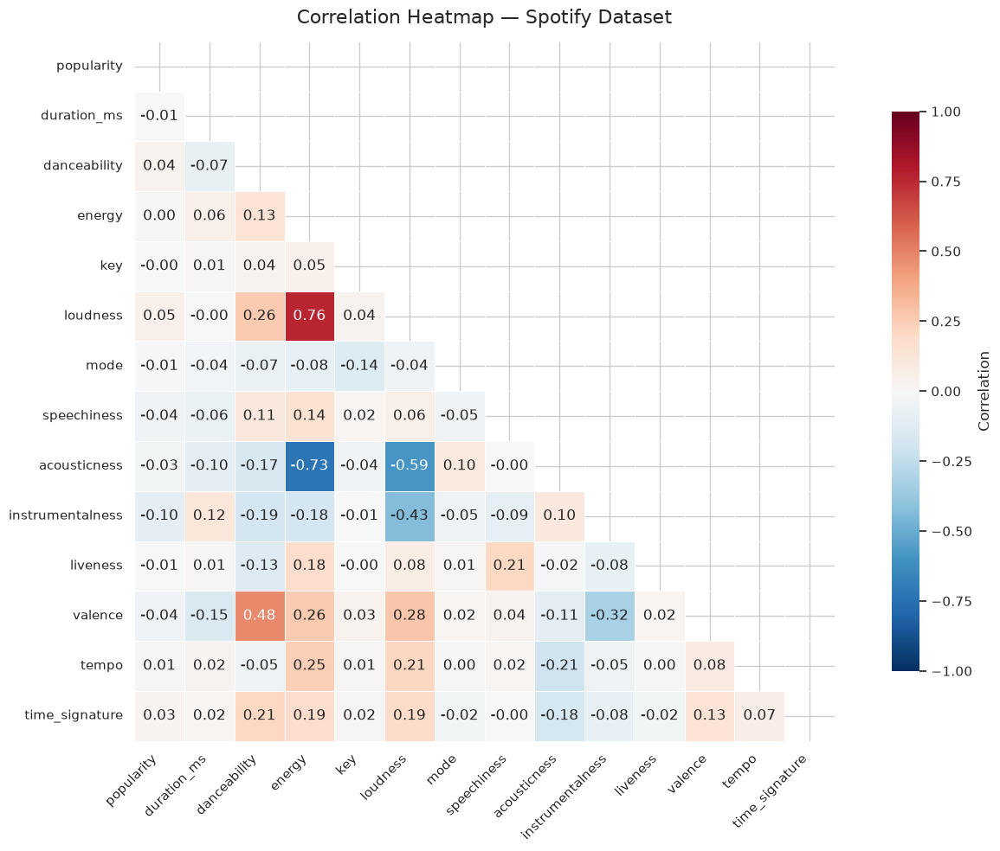

In [34]:
import numpy as np

# Select numerical columns and remove the CSV index column
numeric_df = spotify_df.select_dtypes(include="number").drop(
    columns=["Unnamed: 0"], errors="ignore"
)

# Calculate the correlation matrix
corr_matrix = numeric_df.corr()

# Create a mask to display only the lower triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Plot the heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    corr_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

plt.title("Correlation Heatmap — Spotify Dataset", fontsize=16, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


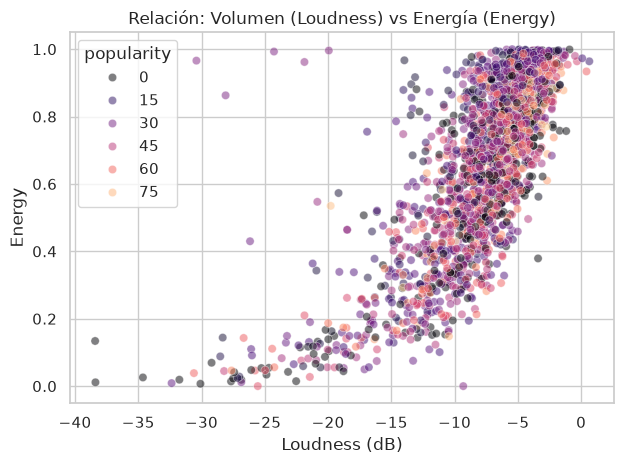

In [35]:
sns.set_theme(style="whitegrid")

sns.scatterplot(
    data=spotify_df.sample(2000, random_state=42),
    x="loudness",
    y="energy",
    alpha=0.5,
    hue="popularity",
    palette="magma"
)

plt.title("Relación: Volumen (Loudness) vs Energía (Energy)")
plt.xlabel("Loudness (dB)")
plt.ylabel("Energy")
plt.tight_layout()
plt.show()

## Generate the Data Profiling Report

### Import the Profiling Tool

In [36]:
from data_profiling import ProfileReport

FG Data Profiling generates an extended analysis of a pandas DataFrame, including descriptive statistics, missing values, distributions, cardinality, correlations, and profiling warnings.

### Create the Profiling Report

In [37]:
spotify_profile = ProfileReport(
    spotify_df,
    title="Spotify Dataset — Data Profiling Report",
)

### Display the Report

In [38]:
spotify_profile = ProfileReport(spotify_df, title="...")

Inspect the report carefully.

Pay particular attention to:

- missing values;
- variable types;
- minimum and maximum values;
- numeric distributions;
- categorical frequencies;
- unique values and cardinality;
- duplicate-related information;
- unusual or suspicious patterns;
- warnings reported by the profiling tool.

### 4.4 Export the Profiling Report

Save the report as an HTML artifact in the project's `reports/` folder.

In [39]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()

REPORT_PATH = (
    PROJECT_ROOT
    / "reports"
    / "spotify_profiling.html"
)

REPORT_PATH.parent.mkdir(
    parents=True,
    exist_ok=True,
)

spotify_profile.to_file(REPORT_PATH)

print("Profiling report saved to:")
print(REPORT_PATH)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 21/21 [00:02<00:00,  8.99it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Profiling report saved to:
/home/sebastiancelorio.dev/Projects/data-engineering/spotify-grammys-etl/notebooks/spotify/reports/spotify_profiling.html


The generated report should now be available at:

`reports/candidates_profiling.html`

This file is a profiling artifact that can be reviewed without regenerating the report.

In [40]:
spotify_profile.to_notebook_iframe()